## 1. Environment and reproducibility

In [1]:
# ============================================================
# 05_baseline_segmentation_cnn
# Section 1: Environment and reproducibility
# ============================================================

import os
import sys
import json
import random
import time
import copy
import warnings

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Running on CPU.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 2. Project configuration

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# Section 2: Project configuration
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/AAI-521/project"
)

CAMVID_ROOT = PROJECT_ROOT / "datasets" / "camvid"

PREPROCESSED_DIR = (
    CAMVID_ROOT / "preprocessed"
)

IMAGE_DIR = CAMVID_ROOT / "images"

# Update this path to the extracted Bluechannel dataset.
BLUECHANNEL_MASK_DIR = (
    CAMVID_ROOT / "bluechannel"
)

# Existing preprocessing artifacts
MASTER_METADATA = (
    PREPROCESSED_DIR /
    "camvid_preprocessed_metadata.csv"
)

ACTIVE_CLASSES_FILE = (
    PREPROCESSED_DIR /
    "active_classes.csv"
)

TRAIN_METADATA = (
    PREPROCESSED_DIR /
    "train_metadata.csv"
)

VAL_METADATA = (
    PREPROCESSED_DIR /
    "validation_metadata.csv"
)

TEST_METADATA = (
    PREPROCESSED_DIR /
    "test_metadata.csv"
)

AUGMENTATION_CONFIG = (
    PREPROCESSED_DIR /
    "augmentation_config.json"
)

# Model configuration
IMAGE_SIZE = 224
NUM_CLASSES = 29
IGNORE_INDEX = 255

BATCH_SIZE = 8
NUM_WORKERS = 2

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5

# Output artifacts
MODEL_OUTPUT_DIR = (
    CAMVID_ROOT / "models" / "baseline_segmentation"
)

MODEL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT)
print("CamVid root:", CAMVID_ROOT)
print("Preprocessed directory:", PREPROCESSED_DIR)
print("Bluechannel masks:", BLUECHANNEL_MASK_DIR)
print("Model output:", MODEL_OUTPUT_DIR)

Project root: /content/drive/MyDrive/AAI-521/project
CamVid root: /content/drive/MyDrive/AAI-521/project/datasets/camvid
Preprocessed directory: /content/drive/MyDrive/AAI-521/project/datasets/camvid/preprocessed
Bluechannel masks: /content/drive/MyDrive/AAI-521/project/datasets/camvid/bluechannel
Model output: /content/drive/MyDrive/AAI-521/project/datasets/camvid/models/baseline_segmentation


## 3. Verify existing preprocessing artifacts

In [4]:
# ============================================================
# Section 2.1: Validate existing preprocessing artifacts
# ============================================================

required_files = {
    "Master metadata": MASTER_METADATA,
    "Active classes": ACTIVE_CLASSES_FILE,
    "Training metadata": TRAIN_METADATA,
    "Validation metadata": VAL_METADATA,
    "Test metadata": TEST_METADATA,
    "Augmentation config": AUGMENTATION_CONFIG,
}

for name, path in required_files.items():
    print(
        f"{name:25s}: "
        f"{'FOUND' if path.exists() else 'MISSING'}"
    )

print("\nBluechannel directory:",
      "FOUND" if BLUECHANNEL_MASK_DIR.exists() else "MISSING")

Master metadata          : FOUND
Active classes           : FOUND
Training metadata        : FOUND
Validation metadata      : FOUND
Test metadata            : FOUND
Augmentation config      : FOUND

Bluechannel directory: FOUND


## 4. Load existing metadata

In [5]:
# ============================================================
# Section 2.2: Load existing metadata
# ============================================================

master_df = pd.read_csv(MASTER_METADATA)

active_classes_df = pd.read_csv(
    ACTIVE_CLASSES_FILE
)

train_df = pd.read_csv(TRAIN_METADATA)
val_df = pd.read_csv(VAL_METADATA)
test_df = pd.read_csv(TEST_METADATA)

with open(AUGMENTATION_CONFIG, "r") as f:
    augmentation_config = json.load(f)

print("Master metadata:", master_df.shape)
print("Active classes:", active_classes_df.shape)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nMaster metadata columns:")
print(master_df.columns.tolist())

print("\nActive class metadata:")
display(active_classes_df.head())

print("\nAugmentation configuration:")
print(json.dumps(augmentation_config, indent=2))

Master metadata: (701, 41)
Active classes: (29, 1)

Split sizes:
Train: 406
Validation: 171
Test: 124

Master metadata columns:
['image', 'filename', 'mask', 'Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall', 'number_of_classes', 'sequence_id', 'split', 'image_path', 'mask_path', 'image_exists', 'mask_exists']

Active class metadata:


,class_name
0,Road
1,Sky
2,Column_Pole
3,LaneMkgsDriv
4,Building



Augmentation configuration:
{
  "seed": 42,
  "image_size": [
    224,
    224
  ],
  "batch_size": 32,
  "active_classes": [
    "Road",
    "Sky",
    "Column_Pole",
    "LaneMkgsDriv",
    "Building",
    "Sidewalk",
    "Car",
    "Pedestrian",
    "Tree",
    "Misc_Text",
    "TrafficLight",
    "Wall",
    "OtherMoving",
    "SignSymbol",
    "Bicyclist",
    "Fence",
    "SUVPickupTruck",
    "VegetationMisc",
    "CartLuggagePram",
    "ParkingBlock",
    "Truck_Bus",
    "Child",
    "Archway",
    "RoadShoulder",
    "Animal",
    "TrafficCone",
    "MotorcycleScooter",
    "LaneMkgsNonDriv",
    "Bridge"
  ],
  "training_augmentations": {
    "horizontal_flip_probability": 0.5,
    "brightness": 0.15,
    "contrast": 0.15,
    "saturation": 0.1,
    "rotation_degrees": 3,
    "translation": [
      0.02,
      0.02
    ],
    "scale": [
      0.98,
      1.02
    ],
    "gaussian_blur_probability": 0.15
  },
  "evaluation_augmentation": false
}


## 5. Inspect Bluechannel masks

In [6]:
# ============================================================
# Section 3: Bluechannel mask inspection
# ============================================================

bluechannel_files = sorted(
    BLUECHANNEL_MASK_DIR.rglob("*.png")
)

print("Total Bluechannel PNG files:",
      len(bluechannel_files))

print("\nSample filenames:")

for path in bluechannel_files[:10]:
    print(path.name)

Total Bluechannel PNG files: 700

Sample filenames:
0001TP_006690.png
0001TP_006720.png
0001TP_006750.png
0001TP_006780.png
0001TP_006810.png
0001TP_006840.png
0001TP_006870.png
0001TP_006900.png
0001TP_006930.png
0001TP_006960.png


In [7]:
# ============================================================
# Section 3.1: Inspect Bluechannel encoding
# ============================================================

if len(bluechannel_files) == 0:
    raise FileNotFoundError(
        "No Bluechannel PNG files found. "
        "Verify BLUECHANNEL_MASK_DIR."
    )

sample_mask_path = bluechannel_files[0]

sample_mask = cv2.imread(
    str(sample_mask_path),
    cv2.IMREAD_UNCHANGED
)

print("Sample mask:", sample_mask_path.name)
print("Shape:", sample_mask.shape)
print("Data type:", sample_mask.dtype)

if sample_mask.ndim == 3:
    print("Unique values per channel:")

    for channel in range(sample_mask.shape[2]):
        values = np.unique(sample_mask[:, :, channel])
        print(
            f"Channel {channel}:",
            values[:40],
            "| Total unique:", len(values)
        )

else:
    print("Unique values:",
          np.unique(sample_mask)[:40])

Sample mask: 0001TP_006690.png
Shape: (720, 960, 3)
Data type: uint8
Unique values per channel:
Channel 0: [ 5  6  9 11 13 15 17 18 20 22 23 25 27 28 31] | Total unique: 15
Channel 1: [0] | Total unique: 1
Channel 2: [0] | Total unique: 1


In [8]:
# ============================================================
# Section 3.2: Global Bluechannel class-index validation
# ============================================================

global_class_counts = Counter()

for mask_path in bluechannel_files:

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_UNCHANGED
    )

    if mask is None:
        print("WARNING: Unable to read:", mask_path)
        continue

    if mask.ndim == 3:
        class_map = mask[:, :, 0]
    else:
        class_map = mask

    values, counts = np.unique(
        class_map,
        return_counts=True
    )

    for value, count in zip(values, counts):
        global_class_counts[int(value)] += int(count)

print("Total masks inspected:", len(bluechannel_files))

print("\nGlobal source class-index distribution:")

for class_id, pixel_count in sorted(
    global_class_counts.items()
):
    print(
        f"Class index {class_id:3d}: "
        f"{pixel_count:,} pixels"
    )

print("\nUnique source class indices:")
print(sorted(global_class_counts.keys()))

Total masks inspected: 700

Global source class-index distribution:
Class index   1: 23,564 pixels
Class index   2: 310,760 pixels
Class index   3: 2,542,545 pixels
Class index   4: 218,198 pixels
Class index   5: 110,087,699 pixels
Class index   6: 16,494,632 pixels
Class index   7: 145,330 pixels
Class index   8: 136,206 pixels
Class index   9: 4,768,256 pixels
Class index  10: 6,921,061 pixels
Class index  11: 8,208,469 pixels
Class index  12: 66,664 pixels
Class index  13: 2,842,307 pixels
Class index  14: 48,677 pixels
Class index  15: 1,933,487 pixels
Class index  16: 1,618,797 pixels
Class index  17: 3,094,283 pixels
Class index  18: 132,052,317 pixels
Class index  19: 1,236,703 pixels
Class index  20: 30,659,061 pixels
Class index  21: 569,021 pixels
Class index  22: 76,714,328 pixels
Class index  23: 3,401,178 pixels
Class index  24: 15,758 pixels
Class index  25: 1,792,774 pixels
Class index  27: 50,535,284 pixels
Class index  28: 2,605,699 pixels
Class index  29: 4 pixels
Cl

In [9]:
# ============================================================
# Section 3.3: Inspect active class definitions
# ============================================================

print("Active classes CSV columns:")
print(active_classes_df.columns.tolist())

display(
    active_classes_df.to_string(index=False)
)

Active classes CSV columns:
['class_name']


'       class_name\n             Road\n              Sky\n      Column_Pole\n     LaneMkgsDriv\n         Building\n         Sidewalk\n              Car\n       Pedestrian\n             Tree\n        Misc_Text\n     TrafficLight\n             Wall\n      OtherMoving\n       SignSymbol\n        Bicyclist\n            Fence\n   SUVPickupTruck\n   VegetationMisc\n  CartLuggagePram\n     ParkingBlock\n        Truck_Bus\n            Child\n          Archway\n     RoadShoulder\n           Animal\n      TrafficCone\nMotorcycleScooter\n  LaneMkgsNonDriv\n           Bridge'

In [10]:
print("Number of active classes:", len(active_classes_df))

print("\nClass names with their positions:")
for idx, name in enumerate(active_classes_df["class_name"], start=0):
    print(f"Model ID {idx:2d}: {repr(name)}")

print("\nDuplicate class names:")
print(active_classes_df["class_name"].duplicated().sum())

Number of active classes: 29

Class names with their positions:
Model ID  0: 'Road'
Model ID  1: 'Sky'
Model ID  2: 'Column_Pole'
Model ID  3: 'LaneMkgsDriv'
Model ID  4: 'Building'
Model ID  5: 'Sidewalk'
Model ID  6: 'Car'
Model ID  7: 'Pedestrian'
Model ID  8: 'Tree'
Model ID  9: 'Misc_Text'
Model ID 10: 'TrafficLight'
Model ID 11: 'Wall'
Model ID 12: 'OtherMoving'
Model ID 13: 'SignSymbol'
Model ID 14: 'Bicyclist'
Model ID 15: 'Fence'
Model ID 16: 'SUVPickupTruck'
Model ID 17: 'VegetationMisc'
Model ID 18: 'CartLuggagePram'
Model ID 19: 'ParkingBlock'
Model ID 20: 'Truck_Bus'
Model ID 21: 'Child'
Model ID 22: 'Archway'
Model ID 23: 'RoadShoulder'
Model ID 24: 'Animal'
Model ID 25: 'TrafficCone'
Model ID 26: 'MotorcycleScooter'
Model ID 27: 'LaneMkgsNonDriv'
Model ID 28: 'Bridge'

Duplicate class names:
0


In [11]:
# Standard CamVid Bluechannel source class ordering
SOURCE_CLASS_NAMES = [
    "Animal",
    "Archway",
    "Bicyclist",
    "Bridge",
    "Building",
    "Car",
    "CartLuggagePram",
    "Child",
    "Column_Pole",
    "Fence",
    "LaneMkgsDriv",
    "LaneMkgsNonDriv",
    "Misc_Text",
    "MotorcycleScooter",
    "OtherMoving",
    "ParkingBlock",
    "Pedestrian",
    "Road",
    "RoadShoulder",
    "Sidewalk",
    "SignSymbol",
    "Sky",
    "SUVPickupTruck",
    "TrafficCone",
    "TrafficLight",
    "Train",
    "Tree",
    "Truck_Bus",
    "Tunnel",
    "VegetationMisc",
    "Void",
    "Wall",
]

# Model IDs are determined by active_classes.csv ordering
CLASS_TO_MODEL_ID = {
    name: idx
    for idx, name in enumerate(active_classes_df["class_name"])
}

# Source ID -> model ID (or IGNORE_INDEX)
SOURCE_ID_TO_MODEL_ID = {}

for source_id, class_name in enumerate(SOURCE_CLASS_NAMES, start=1):
    SOURCE_ID_TO_MODEL_ID[source_id] = (
        CLASS_TO_MODEL_ID.get(class_name, IGNORE_INDEX)
    )

# Display mapping
mapping_df = pd.DataFrame([
    {
        "source_id": source_id,
        "class_name": class_name,
        "model_id": SOURCE_ID_TO_MODEL_ID[source_id]
    }
    for source_id, class_name in enumerate(SOURCE_CLASS_NAMES, start=1)
])

display(mapping_df)

# Basic validation
assert len(CLASS_TO_MODEL_ID) == 29
assert len(SOURCE_ID_TO_MODEL_ID) == 32
assert sum(v != IGNORE_INDEX for v in SOURCE_ID_TO_MODEL_ID.values()) == 29

print("Mapping validation successful.")

,source_id,class_name,model_id
0,1,Animal,24
1,2,Archway,22
2,3,Bicyclist,14
3,4,Bridge,28
4,5,Building,4
5,6,Car,6
6,7,CartLuggagePram,18
7,8,Child,21
8,9,Column_Pole,2
9,10,Fence,15


Mapping validation successful.


In [12]:
mapping_df = pd.DataFrame([
    {
        "source_id": source_id,
        "class_name": class_name,
        "model_id": SOURCE_ID_TO_MODEL_ID[source_id]
    }
    for source_id, class_name in enumerate(SOURCE_CLASS_NAMES, start=1)
])

display(mapping_df)

,source_id,class_name,model_id
0,1,Animal,24
1,2,Archway,22
2,3,Bicyclist,14
3,4,Bridge,28
4,5,Building,4
5,6,Car,6
6,7,CartLuggagePram,18
7,8,Child,21
8,9,Column_Pole,2
9,10,Fence,15


In [13]:
def convert_source_mask_to_model_mask(source_mask):
    """
    Convert CamVid Bluechannel source IDs into model class IDs.

    Parameters:
        source_mask: 2D NumPy array containing source IDs (1-32).

    Returns:
        2D NumPy array containing model IDs (0-28)
        and IGNORE_INDEX (255) for excluded classes.
    """
    model_mask = np.full(
        source_mask.shape,
        IGNORE_INDEX,
        dtype=np.uint8
    )

    for source_id, model_id in SOURCE_ID_TO_MODEL_ID.items():
        if model_id != IGNORE_INDEX:
            model_mask[source_mask == source_id] = model_id

    return model_mask

In [14]:
# Read one Bluechannel mask
sample_mask_path = bluechannel_files[0]

source_mask = cv2.imread(
    str(sample_mask_path),
    cv2.IMREAD_UNCHANGED
)

# Extract channel 0
source_mask = (
    source_mask[:, :, 0]
    if source_mask.ndim == 3
    else source_mask
)

# Convert source IDs to model IDs
model_mask = convert_source_mask_to_model_mask(source_mask)

print("Source mask unique IDs:", np.unique(source_mask))
print("Converted mask unique IDs:", np.unique(model_mask))

print("\nConverted mask shape:", model_mask.shape)
print("Ignored pixel count:", np.sum(model_mask == IGNORE_INDEX))

Source mask unique IDs: [ 5  6  9 11 13 15 17 18 20 22 23 25 27 28 31]
Converted mask unique IDs: [  0   1   2   3   4   5   6   7   8   9  10  12  16  20 255]

Converted mask shape: (720, 960)
Ignored pixel count: 28603


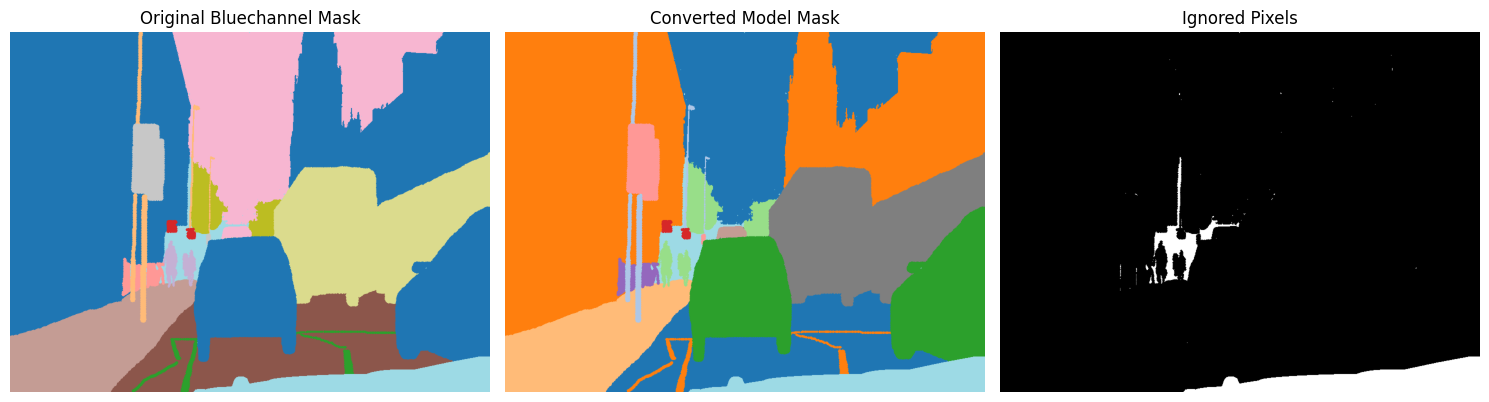

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source_mask, cmap="tab20")
plt.title("Original Bluechannel Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(model_mask, cmap="tab20", vmin=0, vmax=28)
plt.title("Converted Model Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(model_mask == IGNORE_INDEX, cmap="gray")
plt.title("Ignored Pixels")
plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Confirm ignored pixels correspond exactly to source ID 31 (Void)
source_void_count = np.sum(source_mask == 31)
converted_ignore_count = np.sum(model_mask == IGNORE_INDEX)

print("Source Void pixels:", source_void_count)
print("Converted ignored pixels:", converted_ignore_count)

assert source_void_count == converted_ignore_count

# Confirm no invalid model IDs exist
valid_model_ids = set(range(NUM_CLASSES)) | {IGNORE_INDEX}

assert set(np.unique(model_mask)).issubset(valid_model_ids)

print("Mask conversion validation passed.")

Source Void pixels: 28603
Converted ignored pixels: 28603
Mask conversion validation passed.


In [17]:
bluechannel_files = list(BLUECHANNEL_MASK_DIR.rglob("*.png"))

print("Total mask files:", len(bluechannel_files))
print("Unique mask filenames:", len({p.stem for p in bluechannel_files}))

print("\nMaster metadata columns:")
print(master_df.columns.tolist())

display(master_df.head())

Total mask files: 700
Unique mask filenames: 700

Master metadata columns:
['image', 'filename', 'mask', 'Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall', 'number_of_classes', 'sequence_id', 'split', 'image_path', 'mask_path', 'image_exists', 'mask_exists']


,image,filename,mask,Animal,Archway,Bicyclist,Bridge,Building,Car,CartLuggagePram,...,Tunnel,VegetationMisc,Wall,number_of_classes,sequence_id,split,image_path,mask_path,image_exists,mask_exists
0,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006690,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,0,...,0,0,0,14,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
1,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006720,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
2,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006750,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
3,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006780,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
4,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006810,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,0,0,0,18,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True


In [18]:
from pathlib import Path

# Expected filenames from master metadata
expected_stems = set(
    master_df["filename"].astype(str).str.replace(
        r"\.(png|jpg|jpeg)$", "", regex=True, case=False
    )
)

# Actual Bluechannel mask filenames
actual_stems = {
    Path(p).stem for p in bluechannel_files
}

missing_masks = sorted(expected_stems - actual_stems)
unexpected_masks = sorted(actual_stems - expected_stems)

print("Master metadata rows:", len(master_df))
print("Expected unique filenames:", len(expected_stems))
print("Actual Bluechannel masks:", len(actual_stems))

print("\nMissing Bluechannel masks:", len(missing_masks))
print(missing_masks)

print("\nUnexpected Bluechannel masks:", len(unexpected_masks))
print(unexpected_masks)

Master metadata rows: 701
Expected unique filenames: 701
Actual Bluechannel masks: 700

Missing Bluechannel masks: 1
['Seq05VD_f02610']

Unexpected Bluechannel masks: 0
[]


In [19]:
missing_row = master_df[
    master_df["filename"].astype(str).str.replace(
        r"\.(png|jpg|jpeg)$", "",
        regex=True,
        case=False
    ) == "Seq05VD_f02610"
]

display(
    missing_row[
        ["filename", "sequence_id", "split",
         "image_exists", "mask_exists"]
    ]
)

,filename,sequence_id,split,image_exists,mask_exists
617,Seq05VD_f02610,Seq05VD,validation,True,True


In [20]:
valid_metadata = master_df[
    master_df["filename"].astype(str).str.replace(
        r"\.(png|jpg|jpeg)$", "",
        regex=True,
        case=False
    ) != "Seq05VD_f02610"
].copy()

print("Effective dataset size:", len(valid_metadata))

print("\nEffective split distribution:")
display(valid_metadata["split"].value_counts().to_frame("image_count"))

Effective dataset size: 700

Effective split distribution:


,image_count
split,
train,406
validation,170
test,124


### Dataset Annotation Exclusion

The original CamVid dataset contains 701 image/annotation pairs. However, the official CamVid Bluechannel conversion script deliberately excludes `Seq05VD_f02610` because its annotation contains colors outside the defined class-label palette.

Consequently, the Bluechannel dataset contains 700 image/mask pairs. This project uses the 700 valid converted pairs for semantic segmentation to maintain consistent label encoding and avoid introducing uncertain ground-truth annotations.

The excluded image is not used for training, validation, or testing.

## 4. Finalize the segmentation dataset

In [21]:
# Exclude the image intentionally skipped by official CamVid conversion
EXCLUDED_FILENAME = "Seq05VD_f02610"

# Remove extension from metadata filenames for consistent matching
master_df["filename_stem"] = (
    master_df["filename"]
    .astype(str)
    .apply(lambda x: Path(x).stem)
)

# Build a lookup of available Bluechannel masks
bluechannel_lookup = {
    p.stem: str(p)
    for p in bluechannel_files
}

# Exclude the intentionally omitted image
segmentation_df = master_df[
    master_df["filename_stem"] != EXCLUDED_FILENAME
].copy()

# Match Bluechannel masks
segmentation_df["bluechannel_mask_path"] = (
    segmentation_df["filename_stem"].map(bluechannel_lookup)
)

# Validate image and mask availability
segmentation_df["segmentation_image_exists"] = (
    segmentation_df["image_path"].apply(
        lambda p: Path(p).exists()
    )
)

segmentation_df["bluechannel_mask_exists"] = (
    segmentation_df["bluechannel_mask_path"].notna()
)

print("Final segmentation dataset size:", len(segmentation_df))

print("\nImage availability:")
print(segmentation_df["segmentation_image_exists"].value_counts())

print("\nBluechannel mask availability:")
print(segmentation_df["bluechannel_mask_exists"].value_counts())

print("\nMissing image files:")
display(
    segmentation_df[
        ~segmentation_df["segmentation_image_exists"]
    ][["filename", "split"]]
)

print("\nMissing Bluechannel masks:")
display(
    segmentation_df[
        ~segmentation_df["bluechannel_mask_exists"]
    ][["filename", "split"]]
)

Final segmentation dataset size: 700

Image availability:
segmentation_image_exists
True    700
Name: count, dtype: int64

Bluechannel mask availability:
bluechannel_mask_exists
True    700
Name: count, dtype: int64

Missing image files:


,filename,split



Missing Bluechannel masks:


,filename,split


In [22]:
# Verify split distribution
print("Final segmentation split distribution:")

split_summary = (
    segmentation_df.groupby("split")
    .agg(
        image_count=("filename", "count"),
        image_files_available=("segmentation_image_exists", "sum"),
        masks_available=("bluechannel_mask_exists", "sum")
    )
    .reset_index()
)

display(split_summary)

# Create split-specific metadata
train_df = segmentation_df[
    segmentation_df["split"] == "train"
].copy()

val_df = segmentation_df[
    segmentation_df["split"] == "validation"
].copy()

test_df = segmentation_df[
    segmentation_df["split"] == "test"
].copy()

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Final segmentation split distribution:


,split,image_count,image_files_available,masks_available
0,test,124,124,124
1,train,406,406,406
2,validation,170,170,170



Train: 406
Validation: 170
Test: 124
Total: 700


In [23]:
# Enforce dataset integrity
assert len(segmentation_df) == 700, (
    f"Expected 700 samples, found {len(segmentation_df)}"
)

assert segmentation_df["filename_stem"].is_unique, (
    "Duplicate image filenames detected"
)

assert segmentation_df["segmentation_image_exists"].all(), (
    "Some original images are missing"
)

assert segmentation_df["bluechannel_mask_exists"].all(), (
    "Some Bluechannel masks are missing"
)

assert len(train_df) + len(val_df) + len(test_df) == 700

assert set(train_df["filename_stem"]).isdisjoint(
    set(val_df["filename_stem"])
)

assert set(train_df["filename_stem"]).isdisjoint(
    set(test_df["filename_stem"])
)

assert set(val_df["filename_stem"]).isdisjoint(
    set(test_df["filename_stem"])
)

print("Dataset integrity validation passed.")

Dataset integrity validation passed.


## 5. PyTorch Dataset implementation
The key requirement is that image resizing and mask resizing must use different interpolation methods:
- Images: bilinear interpolation.
- Segmentation masks: nearest-neighbor interpolation.
This prevents interpolation from creating invalid class IDs in categorical masks.

In [24]:
# define the segmentation data class
class CamVidSegmentationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_size=224,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load original image
        image = cv2.imread(
            str(row["image_path"]),
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise FileNotFoundError(row["image_path"])

        # OpenCV BGR -> RGB
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Load Bluechannel mask
        source_mask = cv2.imread(
            str(row["bluechannel_mask_path"]),
            cv2.IMREAD_UNCHANGED
        )

        if source_mask is None:
            raise FileNotFoundError(
                row["bluechannel_mask_path"]
            )

        # Extract source class IDs from channel 0
        if source_mask.ndim == 3:
            source_mask = source_mask[:, :, 0]

        # Resize image using bilinear interpolation
        image = cv2.resize(
            image,
            (self.image_size, self.image_size),
            interpolation=cv2.INTER_LINEAR
        )

        # Resize categorical mask using nearest-neighbor
        source_mask = cv2.resize(
            source_mask,
            (self.image_size, self.image_size),
            interpolation=cv2.INTER_NEAREST
        )

        # Convert source IDs to model IDs
        model_mask = convert_source_mask_to_model_mask(
            source_mask
        )

        # Convert image to float32 and normalize to [0, 1]
        image = image.astype(np.float32) / 255.0

        # HWC -> CHW
        image = torch.from_numpy(
            image.transpose(2, 0, 1)
        ).float()

        # Mask remains a 2D tensor with integer class IDs
        model_mask = torch.from_numpy(
            model_mask.astype(np.int64)
        ).long()

        # Optional augmentation hook
        if self.transform is not None:
            image, model_mask = self.transform(
                image, model_mask
            )

        return image, model_mask

In [25]:
# Create dataset objects
train_dataset = CamVidSegmentationDataset(
    dataframe=train_df,
    image_size=IMAGE_SIZE
)

val_dataset = CamVidSegmentationDataset(
    dataframe=val_df,
    image_size=IMAGE_SIZE
)

test_dataset = CamVidSegmentationDataset(
    dataframe=test_df,
    image_size=IMAGE_SIZE
)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Dataset sizes:
Train: 406
Validation: 170
Test: 124


In [26]:
# Inspect one training sample
sample_image, sample_mask = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)
print(
    "Image value range:",
    sample_image.min().item(),
    sample_image.max().item()
)

print("\nMask shape:", sample_mask.shape)
print("Mask dtype:", sample_mask.dtype)
print("Mask unique IDs:", torch.unique(sample_mask).tolist())

print(
    "Mask valid:",
    set(torch.unique(sample_mask).tolist()).issubset(
        set(range(NUM_CLASSES)) | {IGNORE_INDEX}
    )
)

Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Image value range: 0.019607843831181526 1.0

Mask shape: torch.Size([224, 224])
Mask dtype: torch.int64
Mask unique IDs: [0, 1, 2, 3, 5, 6, 8, 9, 11, 13, 16, 17, 19, 22, 25, 28, 255]
Mask valid: True


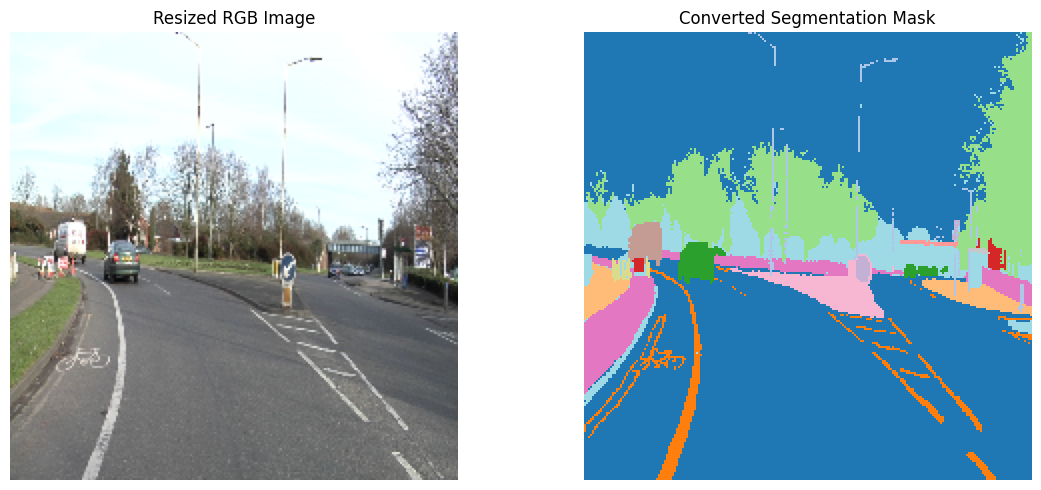

In [27]:
# visualize a dataset sample
image_np = sample_image.permute(1, 2, 0).numpy()
mask_np = sample_mask.numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_np)
axes[0].set_title("Resized RGB Image")
axes[0].axis("off")

axes[1].imshow(
    mask_np,
    cmap="tab20",
    vmin=0,
    vmax=28
)
axes[1].set_title("Converted Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [28]:
# create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

print("DataLoaders created successfully.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully.
Train batches: 51
Validation batches: 22
Test batches: 16


In [29]:
#Validate training batch
images, masks = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print(
    "Image value range:",
    images.min().item(),
    images.max().item()
)

print(
    "Unique mask IDs:",
    torch.unique(masks).tolist()
)

assert images.ndim == 4
assert images.shape[1] == 3

assert masks.ndim == 3
assert masks.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE)

assert masks.dtype == torch.long

assert set(torch.unique(masks).tolist()).issubset(
    set(range(NUM_CLASSES)) | {IGNORE_INDEX}
)

print("\nDataLoader validation passed.")

Batch image shape: torch.Size([8, 3, 224, 224])
Batch mask shape: torch.Size([8, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.int64
Image value range: 0.0 1.0
Unique mask IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 26, 255]

DataLoader validation passed.


## 6. Implement the Baseline Semantic Segmentation CNN
Skip connections pass spatial details from the encoder to the decoder, helping recover object boundaries and smaller structures.

This is a U-Net-inspired baseline, not a pretrained U-Net.

In [30]:
# Define convolution block
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [31]:
# Implement the segmentation CNN
class BaselineSegmentationCNN(nn.Module):

    def __init__(self, num_classes=29):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)

        self.pool = nn.MaxPool2d(kernel_size=2)

        # Bottleneck
        self.bottleneck = ConvBlock(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(64, 32)

        # Pixel-level classification
        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder with skip connections
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        # Return raw logits
        return self.classifier(d1)

In [32]:
# Initialize the model
model = BaselineSegmentationCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Device:", DEVICE)

BaselineSegmentationCNN(
  (enc1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inpl

In [33]:
# Validate the forward pass
model.eval()

with torch.no_grad():

    sample_images, sample_masks = next(iter(train_loader))

    sample_images = sample_images.to(DEVICE)

    logits = model(sample_images)

    predictions = torch.argmax(logits, dim=1)

print("Input shape:", sample_images.shape)
print("Logits shape:", logits.shape)
print("Predictions shape:", predictions.shape)
print("Target shape:", sample_masks.shape)

print("\nPredicted class IDs:")
print(torch.unique(predictions).cpu().tolist())

assert logits.shape == (
    sample_images.shape[0],
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert predictions.shape == sample_masks.shape

print("\nModel forward-pass validation passed.")

Input shape: torch.Size([8, 3, 224, 224])
Logits shape: torch.Size([8, 29, 224, 224])
Predictions shape: torch.Size([8, 224, 224])
Target shape: torch.Size([8, 224, 224])

Predicted class IDs:
[5, 18]

Model forward-pass validation passed.


## 7. Configure model training

In [34]:
# configure loss and optimizer
criterion = nn.CrossEntropyLoss(
    ignore_index=IGNORE_INDEX
)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [35]:
# define the training function
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        # Forward pass
        logits = model(images)

        # Calculate loss
        loss = criterion(logits, masks)

        # Backpropagation
        loss.backward()

        optimizer.step()

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = running_loss / total_samples

    return epoch_loss

In [36]:
#Define the validation function
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            loss = criterion(logits, masks)

            batch_size = images.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

    epoch_loss = running_loss / total_samples

    return epoch_loss

In [37]:
# Training configuration and checkpoint directory
MODEL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    MODEL_OUTPUT_DIR / "baseline_segmentation_best.pth"
)

EARLY_STOPPING_PATIENCE = 5

best_val_loss = float("inf")
epochs_without_improvement = 0

train_losses = []
val_losses = []

print("Checkpoint directory:", MODEL_OUTPUT_DIR)
print("Best model path:", BEST_MODEL_PATH)

Checkpoint directory: /content/drive/MyDrive/AAI-521/project/datasets/camvid/models/baseline_segmentation
Best model path: /content/drive/MyDrive/AAI-521/project/datasets/camvid/models/baseline_segmentation/baseline_segmentation_best.pth


In [38]:
# Execute the training loop
for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Time: {epoch_time:.1f}s"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "class_to_model_id": CLASS_TO_MODEL_ID,
                "num_classes": NUM_CLASSES,
                "image_size": IMAGE_SIZE,
                "ignore_index": IGNORE_INDEX
            },
            BEST_MODEL_PATH
        )

        print("  Best model checkpoint saved.")

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch + 1}."
        )

        break

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_MODEL_PATH)

Epoch [1/30] Train Loss: 2.2879 Val Loss: 1.6685 Time: 196.6s
  Best model checkpoint saved.
Epoch [2/30] Train Loss: 1.3298 Val Loss: 1.2471 Time: 20.6s
  Best model checkpoint saved.
Epoch [3/30] Train Loss: 0.9375 Val Loss: 1.5273 Time: 21.5s
Epoch [4/30] Train Loss: 0.7725 Val Loss: 0.9714 Time: 21.0s
  Best model checkpoint saved.
Epoch [5/30] Train Loss: 0.6959 Val Loss: 0.7913 Time: 20.6s
  Best model checkpoint saved.
Epoch [6/30] Train Loss: 0.6329 Val Loss: 0.9263 Time: 22.9s
Epoch [7/30] Train Loss: 0.5657 Val Loss: 1.1059 Time: 20.5s
Epoch [8/30] Train Loss: 0.5382 Val Loss: 0.7179 Time: 22.4s
  Best model checkpoint saved.
Epoch [9/30] Train Loss: 0.5103 Val Loss: 0.8131 Time: 21.2s
Epoch [10/30] Train Loss: 0.4884 Val Loss: 0.7645 Time: 22.7s
Epoch [11/30] Train Loss: 0.4645 Val Loss: 0.7500 Time: 20.7s
Epoch [12/30] Train Loss: 0.4543 Val Loss: 0.7850 Time: 21.4s
Epoch [13/30] Train Loss: 0.5140 Val Loss: 0.6797 Time: 21.5s
  Best model checkpoint saved.
Epoch [14/30] Tr

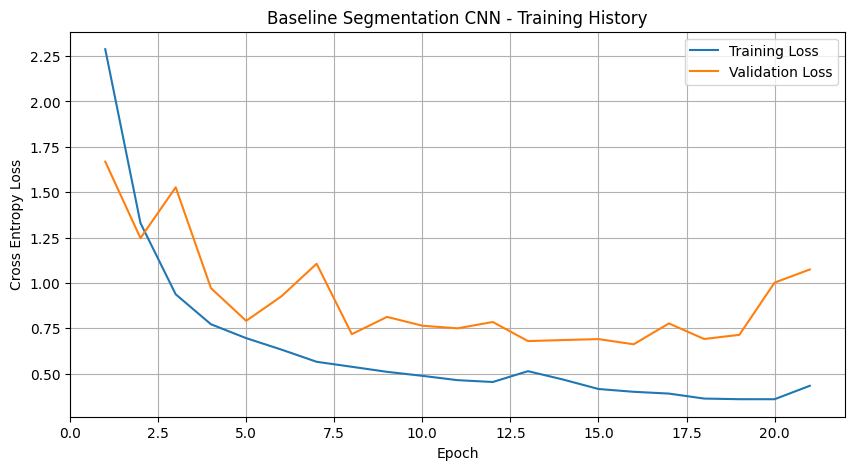

In [39]:
# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Baseline Segmentation CNN - Training History")

plt.legend()
plt.grid(True)
plt.show()

In [40]:
# Load the best checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best checkpoint loaded successfully.
Best epoch: 16
Best validation loss: 0.6621390784488005


In [41]:
# define evaluation metrics
def calculate_segmentation_metrics(
    confusion_matrix,
    class_names
):

    cm = confusion_matrix.astype(np.float64)

    true_positive = np.diag(cm)

    ground_truth_count = cm.sum(axis=1)
    predicted_count = cm.sum(axis=0)

    # Pixel accuracy
    total_pixels = cm.sum()

    pixel_accuracy = (
        true_positive.sum() / total_pixels
        if total_pixels > 0 else 0
    )

    # Per-class accuracy
    class_accuracy = np.divide(
        true_positive,
        ground_truth_count,
        out=np.full(len(class_names), np.nan),
        where=ground_truth_count > 0
    )

    mean_pixel_accuracy = np.nanmean(class_accuracy)

    # Per-class IoU
    union = (
        ground_truth_count
        + predicted_count
        - true_positive
    )

    class_iou = np.divide(
        true_positive,
        union,
        out=np.full(len(class_names), np.nan),
        where=union > 0
    )

    mean_iou = np.nanmean(class_iou)

    results_df = pd.DataFrame({
        "class_name": class_names,
        "pixel_accuracy": class_accuracy,
        "iou": class_iou,
        "ground_truth_pixels": ground_truth_count.astype(int)
    })

    return {
        "pixel_accuracy": pixel_accuracy,
        "mean_pixel_accuracy": mean_pixel_accuracy,
        "mean_iou": mean_iou,
        "class_metrics": results_df,
        "confusion_matrix": cm
    }

In [42]:
# Evaluate on the test set
def evaluate_model(model, loader, device, num_classes):

    model.eval()

    confusion = torch.zeros(
        num_classes,
        num_classes,
        dtype=torch.int64,
        device=device
    )

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            # Exclude ignored pixels
            valid = masks != IGNORE_INDEX

            targets = masks[valid]
            preds = predictions[valid]

            # Update confusion matrix
            encoded = targets * num_classes + preds

            batch_confusion = torch.bincount(
                encoded,
                minlength=num_classes * num_classes
            ).reshape(num_classes, num_classes)

            confusion += batch_confusion

    return confusion.cpu().numpy()

In [43]:
#Execute the evaluation
confusion_matrix = evaluate_model(
    model=model,
    loader=test_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES
)

class_names = active_classes_df[
    "class_name"
].tolist()

metrics = calculate_segmentation_metrics(
    confusion_matrix,
    class_names
)

print("Test Pixel Accuracy:",
      round(metrics["pixel_accuracy"], 4))

print("Test Mean Pixel Accuracy:",
      round(metrics["mean_pixel_accuracy"], 4))

print("Test Mean IoU:",
      round(metrics["mean_iou"], 4))

Test Pixel Accuracy: 0.4049
Test Mean Pixel Accuracy: 0.1233
Test Mean IoU: 0.0772


In [44]:
# Per class IoU
class_metrics_df = metrics["class_metrics"]

display(
    class_metrics_df.sort_values(
        "iou",
        ascending=False
    ).round(4)
)

,class_name,pixel_accuracy,iou,ground_truth_pixels
0,Road,0.6096,0.5572,1003524
4,Building,0.9886,0.2886,1222058
5,Sidewalk,0.3672,0.2696,273491
6,Car,0.3207,0.1953,370777
8,Tree,0.1508,0.1444,986583
1,Sky,0.1325,0.1324,1262092
14,Bicyclist,0.0772,0.0493,31980
11,Wall,0.0257,0.0247,135427
15,Fence,0.0239,0.0205,37180
7,Pedestrian,0.0103,0.0100,54807


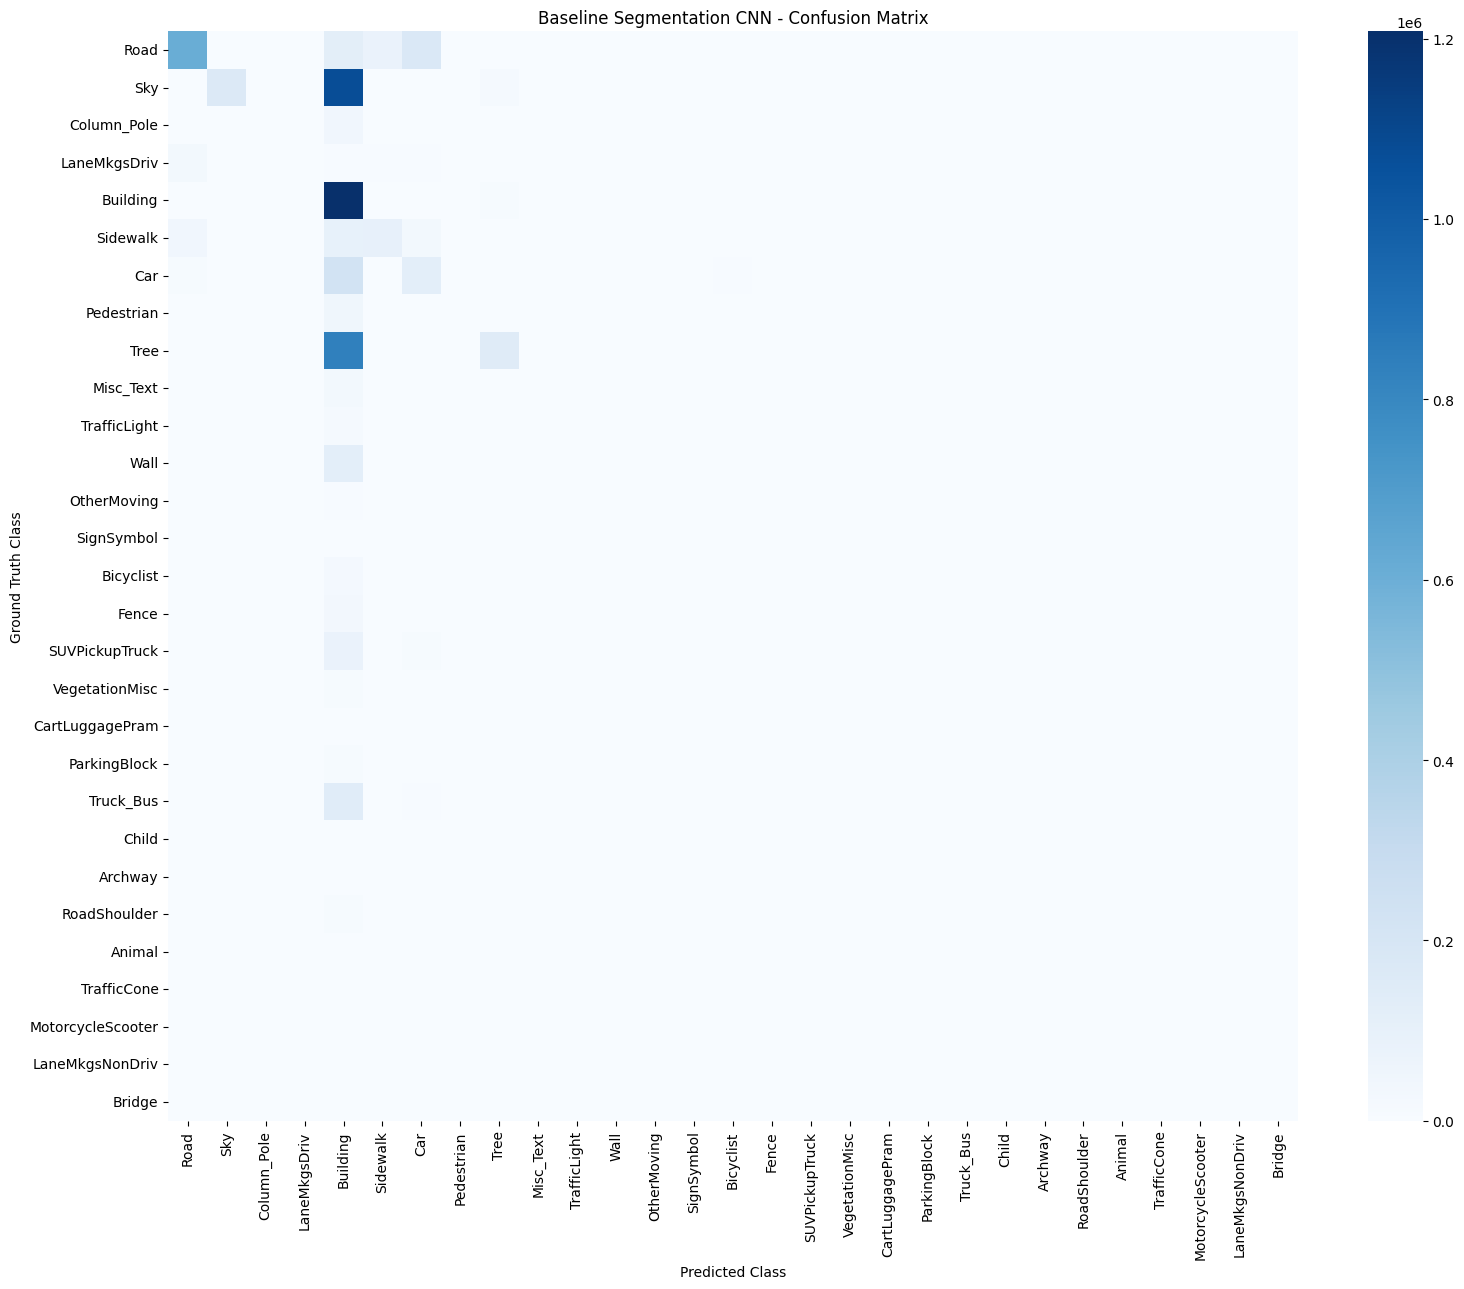

In [46]:
import seaborn as sns

# Visualize result ia confusion matrix
plt.figure(figsize=(16, 13))

sns.heatmap(
    confusion_matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Ground Truth Class")
plt.title("Baseline Segmentation CNN - Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [47]:
# Prediction distribution
def get_prediction_distribution(model, loader, device):

    prediction_counts = np.zeros(
        NUM_CLASSES, dtype=np.int64
    )

    ground_truth_counts = np.zeros(
        NUM_CLASSES, dtype=np.int64
    )

    model.eval()

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            predictions = torch.argmax(logits, dim=1)

            valid = masks != IGNORE_INDEX

            preds = predictions[valid]
            targets = masks[valid]

            prediction_counts += torch.bincount(
                preds.cpu(),
                minlength=NUM_CLASSES
            ).numpy()

            ground_truth_counts += torch.bincount(
                targets.cpu(),
                minlength=NUM_CLASSES
            ).numpy()

    return prediction_counts, ground_truth_counts


pred_counts, gt_counts = get_prediction_distribution(
    model, test_loader, DEVICE
)

distribution_df = pd.DataFrame({
    "class_name": class_names,
    "predicted_pixels": pred_counts,
    "ground_truth_pixels": gt_counts
})

distribution_df["predicted_percentage"] = (
    distribution_df["predicted_pixels"] /
    distribution_df["predicted_pixels"].sum() * 100
)

distribution_df["ground_truth_percentage"] = (
    distribution_df["ground_truth_pixels"] /
    distribution_df["ground_truth_pixels"].sum() * 100
)

display(
    distribution_df.sort_values(
        "predicted_percentage",
        ascending=False
    ).round(2)
)

,class_name,predicted_pixels,ground_truth_pixels,predicted_percentage,ground_truth_percentage
4,Building,4172084,1222058,71.51,20.95
0,Road,706173,1003524,12.10,17.20
6,Car,356976,370777,6.12,6.35
5,Sidewalk,199350,273491,3.42,4.69
8,Tree,192221,986583,3.29,16.91
1,Sky,168378,1262092,2.89,21.63
14,Bicyclist,20572,31980,0.35,0.55
11,Wall,8654,135427,0.15,2.32
15,Fence,6924,37180,0.12,0.64
7,Pedestrian,2046,54807,0.04,0.94


In [49]:
def calculate_split_class_distribution(loader):

    counts = np.zeros(NUM_CLASSES, dtype=np.int64)

    for _, masks in loader:

        masks = masks.numpy()

        valid_masks = masks[masks != IGNORE_INDEX]

        counts += np.bincount(
            valid_masks,
            minlength=NUM_CLASSES
        )

    return counts


train_class_counts = calculate_split_class_distribution(
    train_loader
)

train_distribution_df = pd.DataFrame({
    "class_name": class_names,
    "pixel_count": train_class_counts
})

train_distribution_df["percentage"] = (
    train_distribution_df["pixel_count"] /
    train_distribution_df["pixel_count"].sum() * 100
)

display(
    train_distribution_df.sort_values(
        "percentage",
        ascending=False
    ).round(3)
)

,class_name,pixel_count,percentage
0,Road,6231416,31.288
4,Building,4602402,23.109
1,Sky,3014475,15.136
8,Tree,2112933,10.609
5,Sidewalk,1036357,5.204
6,Car,708675,3.558
3,LaneMkgsDriv,354926,1.782
15,Fence,349843,1.757
2,Column_Pole,182013,0.914
17,VegetationMisc,168890,0.848


In [50]:
# Compare validation and test performance
val_confusion = evaluate_model(
    model=model,
    loader=val_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES
)

val_metrics = calculate_segmentation_metrics(
    val_confusion,
    class_names
)

print("Validation Pixel Accuracy:",
      round(val_metrics["pixel_accuracy"], 4))

print("Validation Mean Pixel Accuracy:",
      round(val_metrics["mean_pixel_accuracy"], 4))

print("Validation Mean IoU:",
      round(val_metrics["mean_iou"], 4))

Validation Pixel Accuracy: 0.8147
Validation Mean Pixel Accuracy: 0.2528
Validation Mean IoU: 0.2059


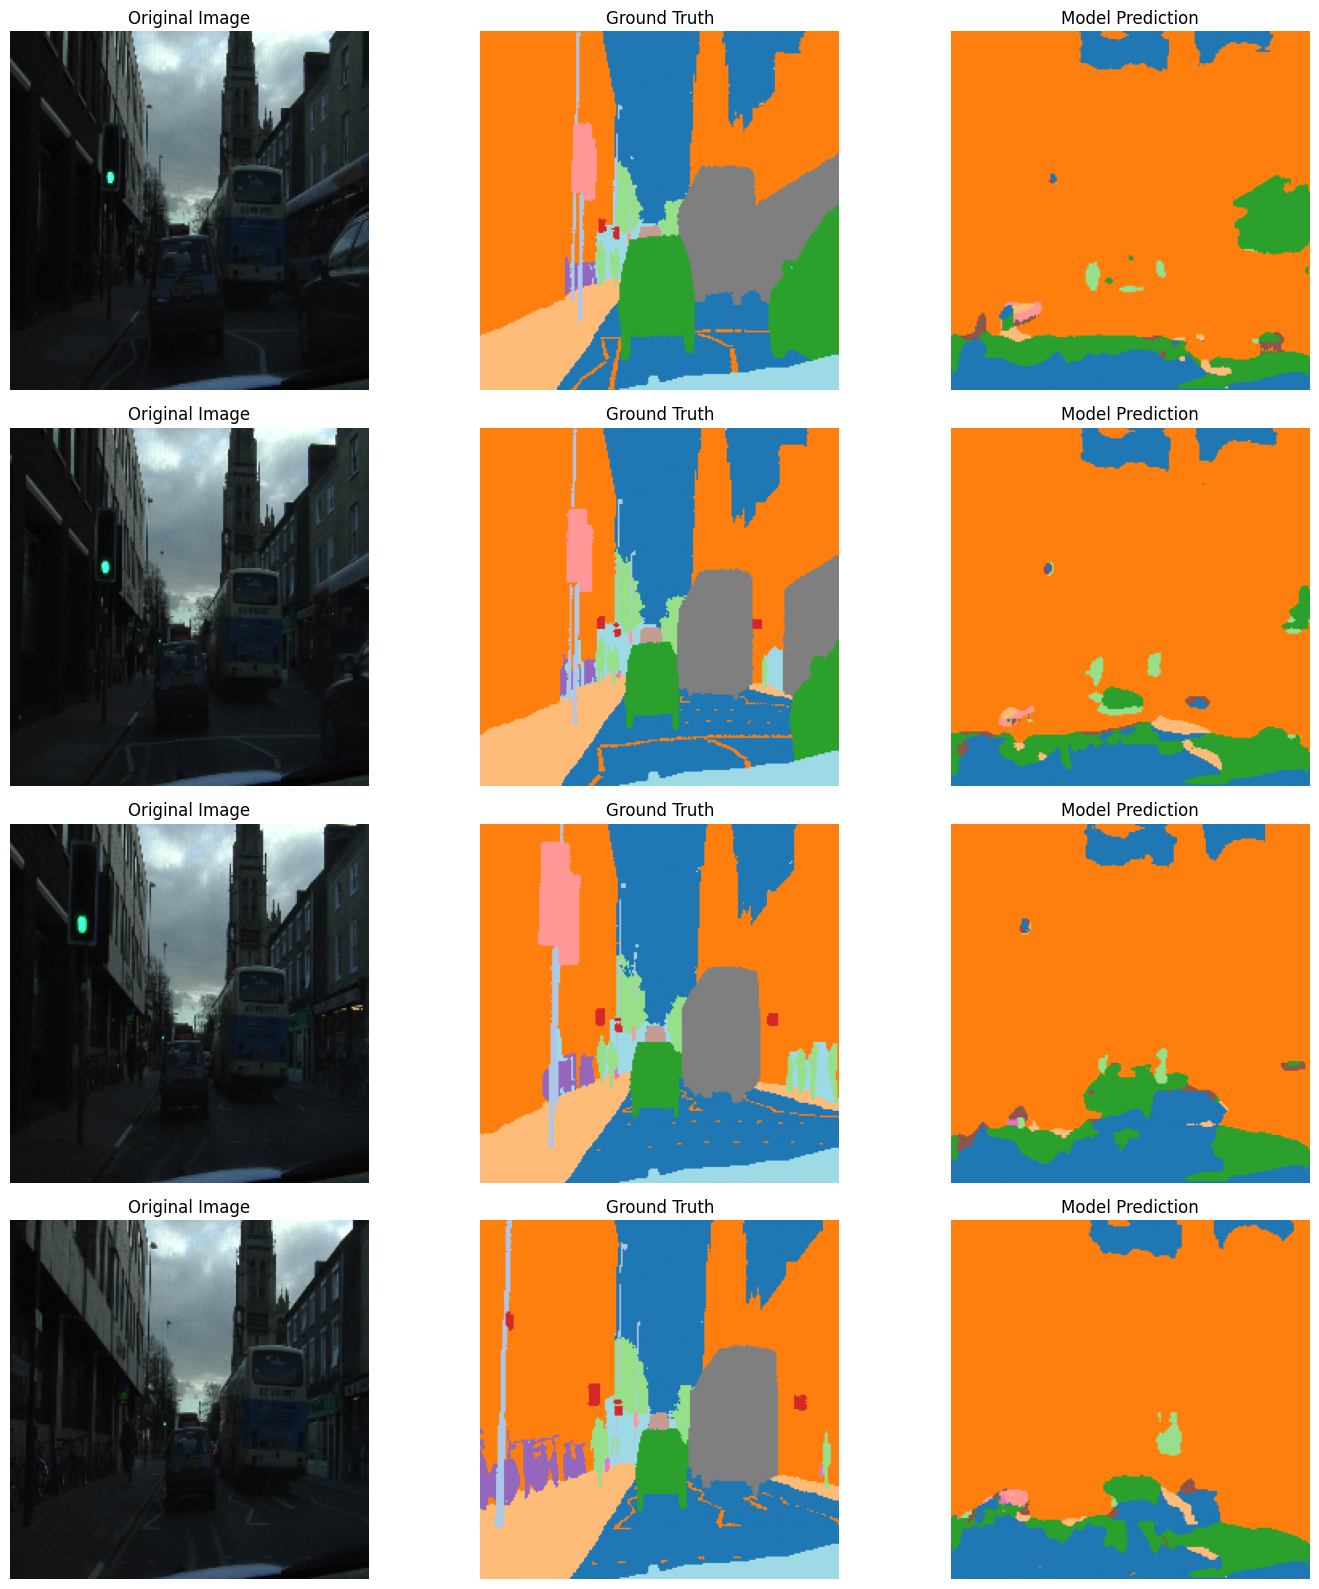

In [51]:
# Visualize actual predictions
images, masks = next(iter(test_loader))

images = images.to(DEVICE)

model.eval()

with torch.no_grad():
    logits = model(images)
    predictions = torch.argmax(logits, dim=1)

images = images.cpu()
masks = masks.cpu()
predictions = predictions.cpu()

fig, axes = plt.subplots(4, 3, figsize=(15, 16))

for i in range(4):

    axes[i, 0].imshow(
        images[i].permute(1, 2, 0).numpy()
    )
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        masks[i].numpy(),
        cmap="tab20",
        vmin=0,
        vmax=28
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        predictions[i].numpy(),
        cmap="tab20",
        vmin=0,
        vmax=28
    )
    axes[i, 2].set_title("Model Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [52]:
print("Sequence distribution by split:")

sequence_summary = pd.crosstab(
    segmentation_df["split"],
    segmentation_df["sequence_id"]
)

display(sequence_summary)

print("\nImage counts by split:")
display(
    segmentation_df.groupby("split").size()
)

Sequence distribution by split:


sequence_id,0001TP,0006R0,0016E5,Seq05VD
split,,,,
test,124,0,0,0
train,0,101,305,0
validation,0,0,0,170



Image counts by split:


,0
split,
test,124
train,406
validation,170


In [53]:
class_columns = active_classes_df["class_name"].tolist()

split_class_distribution = (
    segmentation_df.groupby("split")[class_columns]
    .sum()
)

# Convert to percentage of images containing each class
split_class_percentage = (
    split_class_distribution
    .div(segmentation_df.groupby("split").size(), axis=0)
    * 100
)

display(split_class_percentage.round(2))

,Road,Sky,Column_Pole,LaneMkgsDriv,Building,Sidewalk,Car,Pedestrian,Tree,Misc_Text,...,ParkingBlock,Truck_Bus,Child,Archway,RoadShoulder,Animal,TrafficCone,MotorcycleScooter,LaneMkgsNonDriv,Bridge
split,,,,,,,,,,,,,,,,,,,,,
test,100.0,99.19,99.19,99.19,100.00,100.00,100.00,95.97,100.00,82.26,...,23.39,34.68,0.00,0.00,9.68,0.00,0.00,0.00,0.00,0.00
train,100.0,99.75,99.75,99.01,97.29,92.86,88.18,88.42,87.93,87.19,...,29.56,34.73,32.51,24.38,7.64,0.99,4.19,3.45,1.48,2.46
validation,100.0,100.00,100.00,100.00,98.24,100.00,94.12,94.71,91.18,83.53,...,22.94,0.00,12.94,4.71,7.06,12.94,1.76,0.00,4.12,0.00


In [54]:
def calculate_pixel_distribution(df):

    counts = np.zeros(NUM_CLASSES, dtype=np.int64)

    for _, row in df.iterrows():

        mask = cv2.imread(
            str(row["bluechannel_mask_path"]),
            cv2.IMREAD_UNCHANGED
        )

        if mask is None:
            continue

        if mask.ndim == 3:
            mask = mask[:, :, 0]

        model_mask = convert_source_mask_to_model_mask(mask)

        valid_pixels = model_mask[
            model_mask != IGNORE_INDEX
        ]

        counts += np.bincount(
            valid_pixels,
            minlength=NUM_CLASSES
        )

    return counts


split_pixel_counts = {}

for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    split_pixel_counts[split_name] = (
        calculate_pixel_distribution(split_df)
    )

pixel_distribution_df = pd.DataFrame({
    "class_name": class_names,
    "train_pixels": split_pixel_counts["Train"],
    "validation_pixels": split_pixel_counts["Validation"],
    "test_pixels": split_pixel_counts["Test"]
})

display(pixel_distribution_df)

,class_name,train_pixels,validation_pixels,test_pixels
0,Road,86477379,31672871,13902067
1,Sky,41168576,18289008,17256744
2,Column_Pole,2509945,1568018,690293
3,LaneMkgsDriv,4917618,2557669,733182
4,Building,63171707,30080073,16835919
5,Sidewalk,14257881,12641950,3759230
6,Car,9761288,1619911,5113433
7,Pedestrian,1790440,553492,750351
8,Tree,29052628,7951026,13531630
9,Misc_Text,2025141,404384,412782
